## LLM Extraction Performance Visualization
This script visualizes and compares the paper-level extraction performance of different methods using violin and strip plots. It helps evaluate the impact of prompt optimization on precision, recall, and F1-score across multiple publications.

---

#### **1. Accepts performance evaluation results from:**

- ChEMBL-manual: manually curated gold-standard entries
- LLM-old: extractions using the initial prompt
- LLM-opt: extractions using the optimized prompt

#### **2. Extracts per-paper scores (precision, recall, f1) for evalutation**


#### **3. Combines results into a unified dataframe for plotting**

---

#### **Author Info**  
**Author**: *ziyiyang*  
**Email**:  *chriszyyang@tencent.com*  
**Last Updated**: `2025-07-05`


In [1]:
# === Import Libraries ===
import os
import shutil
import numpy as np
import pandas as pd
from tqdm import tqdm

from pathlib import Path

import re
import math
from collections import defaultdict

import seaborn as sns
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
# === setting path ===
current_path = os.getcwd()
home_dir = os.path.dirname(current_path)

raw_dir = f"{home_dir}/data/benchmark"
result_dir = f"{home_dir}/data/result"

ground_truth = f"{raw_dir}/golden_benchmark_resistance_dataset.csv"
chembl_manual_file = f"{raw_dir}/chembl_extracted_data.csv"
llm_old_file = f"{result_dir}/resistance_deepseek_06091658.csv"
llm_opt_file = f"{result_dir}/resistance_deepseek_06111539.csv"

---
### Step 1. import dataset
---

In [3]:
# 1. import gold-standard dataset
data_true = pd.read_csv(ground_truth)
print(f"Number of papers: {len(data_true['pmc_id'].unique())}")
print(f"Number of samples for  Klebsiella pneumoniae: {data_true.shape[0]}")
data_true.sample(5)

Number of papers: 14
Number of samples for  Klebsiella pneumoniae: 298


,pmc_id,target_name,Strain,antibiotic,standard_type,standard_relation,standard_value,standard_units
109,PMC7104248,Klebsiella pneumoniae,CDC-0361,Piperacillin + compound 3,MIC,=,2,μg/mL
75,PMC7104248,Klebsiella pneumoniae,VIM-4 producer,Meropenem + compound 26,MIC,=,8,μg/mL
105,PMC7104248,Klebsiella pneumoniae,CDC-0066,Piperacillin + AVI,MIC,=,8,μg/mL
94,PMC7104248,Klebsiella pneumoniae,CDC-0040,Piperacillin + compound 1,MIC,=,16,μg/mL
39,PMC7104248,Klebsiella pneumoniae,VIM-4 producer,Meropenem + compound 3,MIC,=,4,μg/mL


In [4]:
# 2. import chembl manual dataset
data_chembl = pd.read_csv(chembl_manual_file)
data_chembl = data_chembl[data_chembl['paper_id'].isin(data_true['pmc_id'].unique())].reset_index(drop=True)
print(f"Number of chembl data: {data_chembl.shape[0]}")
data_chembl.head()

Number of chembl data: 75


,paper_id,canonical_smiles,target_name,standard_type,standard_relation,standard_value,standard_units
0,PMC10945559,C#CCCNC(=O)[C@H]1O[C@@H](n2ccc(N)nc2=O)C=C[C@@...,Klebsiella pneumoniae,IC50,=,30.7,ug.mL-1
1,PMC10945559,C#CCCNC(=O)[C@H]1O[C@@H](n2ccc(N)nc2=O)C=C[C@@...,Klebsiella pneumoniae,MIC,=,128.0,ug ml-1
2,PMC10945559,C#CCNC(=O)[C@H]1O[C@@H](n2ccc(N)nc2=O)C=C[C@@H...,Klebsiella pneumoniae,IC50,=,40.4,ug.mL-1
3,PMC10945559,C#CCNC(=O)[C@H]1O[C@@H](n2ccc(N)nc2=O)C=C[C@@H...,Klebsiella pneumoniae,MIC,=,128.0,ug ml-1
4,PMC8365600,CC(C)C[C@@H]1NC(=O)[C@@H](CC(C)C)NC(=O)[C@H](C...,Klebsiella pneumoniae,MIC,>,64.0,ug.mL-1


In [5]:
# 3. import LLM extracted data (origin)
data_llm_old = pd.read_csv(llm_old_file,  encoding="latin1")
data_llm_old = data_llm_old[data_llm_old['Organism'] == 'Klebsiella pneumoniae '].reset_index(drop=True)
data_llm_old['standard_value'] = data_llm_old['standard_value'].replace(r"[^\d\.\-]", "", regex=True)
data_llm_old['standard_type'] = data_llm_old['standard_type'].replace(r"MIC50", "MIC", regex=True)

data_llm_old['standard_units'] = data_llm_old['standard_units'].replace(r"Î.*g/mL", "μg/mL", regex=True)
data_llm_old['standard_units'] = data_llm_old['standard_units'].replace(r"Î¼M", "μm", regex=True)
data_llm_old['standard_units'] = data_llm_old['standard_units'].replace(r"Î¼g mL-1", "μg/mL", regex=True)

print(f"Number of extracted samples for Klebsiella pneumoniae: {data_llm_old.shape[0]}")
data_llm_old.head()

Number of extracted samples for Klebsiella pneumoniae: 52


,Source,Pubmed,Organism,Strain,Genes,Mutation,Antibiotic,Class of Antibiotic,Mechanism of resistance,standard_relation,standard_type,standard_value,standard_units,Susceptibility,Notes,paper_id
0,Development of pharmacophore models for AcrB p...,10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Colistin,Polymyxins,Efflux pump,â¥,MIC,1024,μg/mL,R,Clinical isolate,PMC10809322
1,Development of pharmacophore models for AcrB p...,10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Colistin + Argatroban,Polymyxins + Thrombin inhibitor,Efflux pump inhibition,=,MIC,256,μg/mL,R,Combination therapy,PMC10809322
2,Development of pharmacophore models for AcrB p...,10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Colistin + CCCP,Polymyxins + Protonophore,Efflux pump inhibition,=,MIC,0.25,μg/mL,S,Combination therapy,PMC10809322
3,Development of pharmacophore models for AcrB p...,10809322,Klebsiella pneumoniae,ATCC 13882,NaN,wild type,Colistin,Polymyxins,NaN,=,MIC,,μg/mL,S,Baseline susceptible strain,PMC10809322
4,Development of pharmacophore models for AcrB p...,10809322,Klebsiella pneumoniae,SDL79,NaN,NaN,Colistin,Polymyxins,Efflux pump,=,MIC,,μg/mL,R,Positive control strain,PMC10809322


In [6]:
# 4. Import LLM-extracted data (optimized prompt version)
data_llm_opt = pd.read_csv(llm_opt_file, encoding="latin1")

# Filter for samples related to Klebsiella pneumoniae
data_llm_opt = data_llm_opt[data_llm_opt['Organism'] == 'Klebsiella pneumoniae'].reset_index(drop=True)

# Clean numeric MIC values: remove non-numeric characters
data_llm_opt['standard_value'] = data_llm_opt['standard_value'].replace(r"[^\d\.\-]", "", regex=True)

# Normalize MIC type labels (e.g., MIC50 → MIC)
data_llm_opt['standard_type'] = data_llm_opt['standard_type'].replace(r"MIC50", "MIC", regex=True)

# Standardize MIC unit expressions
data_llm_opt['standard_units'] = data_llm_opt['standard_units'].replace(r"Î.*g/mL", "μg/mL", regex=True)
data_llm_opt['standard_units'] = data_llm_opt['standard_units'].replace(r"Î¼M", "μm", regex=True)
data_llm_opt['standard_units'] = data_llm_opt['standard_units'].replace(r"Î¼g mL-1", "μg/mL", regex=True)

# Restrict to LLM-extracted entries that match gold-standard PMC IDs
pmc_ids = set(data_true['pmc_id'].unique())
data_llm_opt = data_llm_opt[data_llm_opt['paper_id'].isin(pmc_ids)].reset_index(drop=True)

# Display the total number of valid extractions for Klebsiella pneumoniae
print(f"Number of extracted samples for Klebsiella pneumoniae: {data_llm_opt.shape[0]}")
data_llm_opt.head()

Number of extracted samples for Klebsiella pneumoniae: 105


,Unnamed: 0,Source,Pubmed,Organism,Strain,Genes,Mutation,Antibiotic,Class of Antibiotic,Mechanism of resistance,standard_relation,standard_type,standard_value,standard_units,Susceptibility,Notes,paper_id
0,0,"RSC Med. Chem., 2024",10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Colistin,Polymyxins,Efflux pump,=,MIC,1024,ÃÂ¼g/mL,R,Clinical isolate,PMC10809322
1,3,"RSC Med. Chem., 2024",10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Carbonyl cyanide m-chlorophenylhydrazone (CCCP),Efflux pump inhibitor,Efflux inhibition,=,MIC,5,ÃÂ¼g/mL,NaN,NaN,PMC10809322
2,6,"RSC Med. Chem., 2024",10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Argatroban,Thrombin inhibitor,Efflux inhibition,=,MIC,512,ÃÂ¼g/mL,NaN,NaN,PMC10809322
3,9,"RSC Med. Chem., 2024",10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Colistin + CCCP,Combination,Efflux inhibition,=,MIC,0.25,ÃÂ¼g/mL,NaN,4-fold reduction,PMC10809322
4,12,"RSC Med. Chem., 2024",10809322,Klebsiella pneumoniae,UK48,NaN,NaN,Colistin + Argatroban,Combination,Efflux inhibition,=,MIC,256,ÃÂ¼g/mL,NaN,Synergistic (FICI=0.125),PMC10809322


---
### Step 2. Evaluate the model performance
---

In [7]:
def normalize_value(val):
    """
    Normalize a numeric value by removing units, symbols, whitespace,
    and parsing scientific notation if present.

    Parameters:
        val (str or numeric): Raw value to be cleaned.

    Returns:
        float or None: Parsed float value, or None if invalid.
    """
    if pd.isna(val):
        return None
    val = str(val).strip()
    val = re.sub(r"[^\d\.\-eE\+]", "", val)
    try:
        return float(val)
    except ValueError:
        return None


def get_answer_dict(df):
    """
    Convert a dataframe into a nested dictionary of extracted values grouped by paper and standard type.

    Returns:
        dict: {
            'paper_id_1': {'MIC': [value1, value2], 'EC50': [value3], ...},
            'paper_id_2': {...},
            ...
        }
    """
    answer = defaultdict(lambda: defaultdict(list))
    for _, row in df.iterrows():
        pid = str(row["paper_id"]) if "paper_id" in row else str(row["pmc_id"])
        std_type = str(row["standard_type"]).strip()
        value = normalize_value(row["standard_value"])
        if pd.notna(value):
            answer[pid][std_type].append(value)
    return answer


def compare_answers_by_type_with_paper_stats(gt_dict, pred_dict):
    """
    Compare predicted and ground-truth values for each paper and standard type (e.g., MIC, EC50).
    
    For each (paper_id, type), compute:
        - Number of ground-truth values
        - Number of predicted values
        - Number of matched values
        - Precision, Recall, and F1-score

    Returns:
        dict: {
            'MIC': {
                'per_paper_scores': [...],       # list of paper-level metrics
                'mean_precision': float,
                'std_precision': float,
                'mean_recall': float,
                'std_recall': float,
                'mean_f1': float,
                'std_f1': float
            },
            ...
        }
    """
    result_by_type = defaultdict(list)

    for pid in set(gt_dict.keys()).union(pred_dict.keys()):
        gt_values = gt_dict.get(pid, {})
        pred_values = pred_dict.get(pid, {})

        all_types = set(gt_values.keys()).union(pred_values.keys())
        for std_type in all_types:
            gt_list = gt_values.get(std_type, []).copy()
            pred_list = pred_values.get(std_type, [])

            gt_n = len(gt_list)
            pred_n = len(pred_list)
            match_n = 0

            # Count exact matches and remove matched values from gt_list
            for val in pred_list:
                if val in gt_list:
                    match_n += 1
                    gt_list.remove(val)

            precision = match_n / pred_n if pred_n else 0
            recall = match_n / gt_n if gt_n else 0
            f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0

            result_by_type[std_type].append({
                "paper_id": pid,
                "gt": gt_n,
                "pred": pred_n,
                "match": match_n,
                "precision": precision,
                "recall": recall,
                "f1": f1
            })

    # Compute mean and std across all papers for each metric
    summary = {}
    for std_type, paper_scores in result_by_type.items():
        precisions = [s["precision"] for s in paper_scores]
        recalls = [s["recall"] for s in paper_scores]
        f1s = [s["f1"] for s in paper_scores]

        summary[std_type] = {
            "per_paper_scores": paper_scores,
            "mean_precision": np.mean(precisions),
            "std_precision": np.std(precisions),
            "mean_recall": np.mean(recalls),
            "std_recall": np.std(recalls),
            "mean_f1": np.mean(f1s),
            "std_f1": np.std(f1s),
        }

    return summary


def evaluate_llm_standard_values(gt_df, pred_df):
    """
    Evaluate LLM-extracted values against gold-standard labels.

    Parameters:
        gt_df (pd.DataFrame): Ground truth annotated values
        pred_df (pd.DataFrame): Predicted values by LLM

    Returns:
        dict: Per-type evaluation metrics (see compare_answers_by_type_with_paper_stats)
    """
    gt_dict = get_answer_dict(gt_df)
    pred_dict = get_answer_dict(pred_df)
    return compare_answers_by_type_with_paper_stats(gt_dict, pred_dict)


In [8]:
results_chembl_manual = evaluate_llm_standard_values(gt_df=data_true, pred_df=data_chembl)
results_llm_old = evaluate_llm_standard_values(gt_df=data_true, pred_df=data_llm_old)
results_llm_opt = evaluate_llm_standard_values(gt_df=data_true, pred_df=data_llm_opt)

In [9]:
# Extract per-paper evaluation results for MIC from each method
df_chembl = pd.DataFrame(results_chembl_manual['MIC']['per_paper_scores'])
df_chembl['Method'] = 'ChEMBL Manual'  # Ground-truth aligned entries from ChEMBL

df_pred_before = pd.DataFrame(results_llm_old['MIC']['per_paper_scores'])
df_pred_before['Method'] = 'LLM Extraction (before optimization)'  # Initial prompt

df_pred_opt = pd.DataFrame(results_llm_opt['MIC']['per_paper_scores'])
df_pred_opt['Method'] = 'LLM Extraction (after optimization)'  # Optimized prompt

# Combine all methods into a single DataFrame for comparative visualization
df_compare = pd.concat([df_chembl, df_pred_before, df_pred_opt], ignore_index=True)

# Filter out records where ground-truth (gt) MIC values are missing (i.e., zero)
df_compare = df_compare[df_compare['gt'] != 0].reset_index(drop=True)

# Display the final comparison DataFrame
df_compare

,paper_id,gt,pred,match,precision,recall,f1,Method
0,PMC6660313,2,1,1,1.000000,0.500000,0.666667,ChEMBL Manual
1,PMC6593178,6,1,1,1.000000,0.166667,0.285714,ChEMBL Manual
2,PMC8365600,18,1,1,1.000000,0.055556,0.105263,ChEMBL Manual
3,PMC10945559,9,10,9,0.900000,1.000000,0.947368,ChEMBL Manual
4,PMC9743092,3,1,0,0.000000,0.000000,0.000000,ChEMBL Manual
5,PMC8436411,9,9,9,1.000000,1.000000,1.000000,ChEMBL Manual
6,PMC8958502,2,1,1,1.000000,0.500000,0.666667,ChEMBL Manual
7,PMC6767355,12,1,1,1.000000,0.083333,0.153846,ChEMBL Manual
8,PMC9884090,2,1,1,1.000000,0.500000,0.666667,ChEMBL Manual
9,PMC10809322,25,2,2,1.000000,0.080000,0.148148,ChEMBL Manual


In [10]:
df_compare.groupby('Method')['precision'].mean(), df_compare.groupby('Method')['precision'].median()

(Method
 ChEMBL Manual                           0.904187
 LLM Extraction (after optimization)     0.790394
 LLM Extraction (before optimization)    0.628912
 Name: precision, dtype: float64,
 Method
 ChEMBL Manual                           1.00
 LLM Extraction (after optimization)     1.00
 LLM Extraction (before optimization)    0.95
 Name: precision, dtype: float64)

In [11]:
df_compare.groupby('Method')['recall'].mean(), df_compare.groupby('Method')['recall'].median()

(Method
 ChEMBL Manual                           0.431509
 LLM Extraction (after optimization)     0.604921
 LLM Extraction (before optimization)    0.320130
 Name: recall, dtype: float64,
 Method
 ChEMBL Manual                           0.480769
 LLM Extraction (after optimization)     0.722222
 LLM Extraction (before optimization)    0.115556
 Name: recall, dtype: float64)

In [12]:
df_compare.groupby('Method')['f1'].mean(), df_compare.groupby('Method')['f1'].median()

(Method
 ChEMBL Manual                           0.500444
 LLM Extraction (after optimization)     0.648379
 LLM Extraction (before optimization)    0.366494
 Name: f1, dtype: float64,
 Method
 ChEMBL Manual                           0.649123
 LLM Extraction (after optimization)     0.807692
 LLM Extraction (before optimization)    0.207143
 Name: f1, dtype: float64)

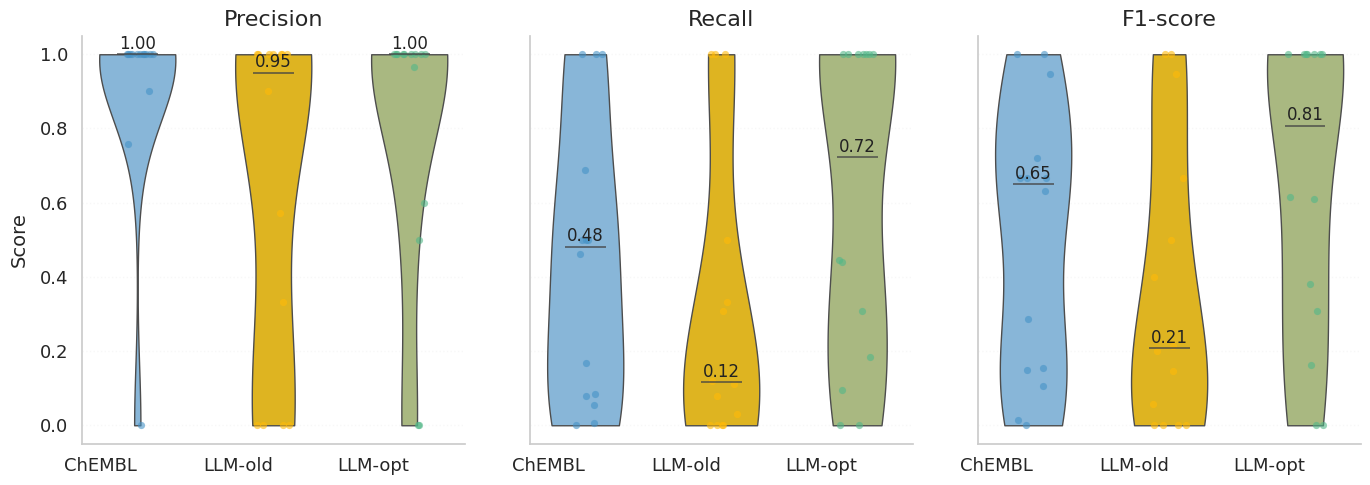

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set the visual theme
sns.set_theme(style="whitegrid", font_scale=1.22)

# Metrics to visualize
metrics = ['precision', 'recall', 'f1']
metric_labels = ['Precision', 'Recall', 'F1-score']

# Standardize method labels
method_order = ['ChEMBL', 'LLM-old', 'LLM-opt']
df_compare['Method'] = df_compare['Method'].replace({
    'ChEMBL Manual': 'ChEMBL',
    'LLM Extraction (before optimization)': 'LLM-old',
    'LLM Extraction (after optimization)': 'LLM-opt'
})

# Color settings
violin_palette = ['#7ab8e6', '#fec601', '#adc178']
strip_palette = ['#4592c6', '#ffba08', '#52b788']

# Initialize subplots: 1 row × 3 columns for each metric
fig, axes = plt.subplots(1, 3, figsize=(16.5, 5.3), sharey=True, gridspec_kw={'wspace': 0.17})

# Plot each metric
for i, (metric, label) in enumerate(zip(metrics, metric_labels)):
    ax = axes[i]
    
    # Violin plot to show value distribution
    sns.violinplot(
        x="Method", y=metric, data=df_compare,
        order=method_order, palette=violin_palette,
        inner=None, linewidth=1.0, cut=0, ax=ax,
        density_norm="area", width=0.56, legend=False
    )

    # Overlay individual paper-level scores (strip plot)
    for j, method in enumerate(method_order):
        sns.stripplot(
            x="Method", y=metric,
            data=df_compare[df_compare["Method"] == method],
            order=method_order, color=strip_palette[j],
            size=5.2, jitter=0.13, alpha=0.6, ax=ax
        )

    # Draw median lines for each method
    medians = df_compare.groupby('Method')[metric].median()
    for j, method in enumerate(method_order):
        median_val = medians[method]
        ax.hlines(median_val, j - 0.15, j + 0.15,
                  colors='#444444', linewidth=1.2, zorder=10, alpha=0.82)
        ax.text(j, median_val + 0.004, f"{median_val:.2f}",
                ha='center', va='bottom', color='#222222', fontsize=12)

    # Axis labels and formatting
    ax.set_title(label, fontsize=16, pad=7)
    ax.set_xlabel("")
    ax.set_xticklabels(method_order, rotation=0, ha='right', fontsize=13)
    ax.set_ylim(-0.05, 1.05)

    if i == 0:
        ax.set_ylabel("Score", fontsize=14, labelpad=8)
    else:
        ax.set_ylabel("")

    ax.tick_params(axis='y', labelsize=13)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(axis='x', visible=False)
    ax.grid(axis='y', linestyle=':', alpha=0.14)

# Adjust layout to prevent overlapping
plt.tight_layout(rect=[0, 0.01, 1, 1])
#plt.savefig(f"{home_dir}/figure/Figure3-LLM_opt_performance.pdf", dpi=300)
plt.show()